In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from skimage import io, filters, morphology, measure, segmentation
from skimage.feature import peak_local_max
from skimage.segmentation import find_boundaries
from scipy import ndimage as ndi

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report

# Functions

In [ ]:
def _plot_image(clean_mask, labels, figsize=(8, 8)):
    fig, ax = plt.subplots(figsize=figsize)

    ax.imshow(
        segmentation.mark_boundaries(
            clean_mask.astype(float),
            labels,
            color=(1, 0, 0)
        )
    )

    ax.set_title(f"Watershed: {labels.max()} objects")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import segmentation, exposure

def plot_image(image, clean_mask, labels, df_subset,
               mode="image", figsize=(8, 8)):

    # Get original segmentation labels from DataFrame subset
    selected_ids = df_subset["label"].astype(int).to_numpy()

    # Keep only selected objects
    selected_labels = np.where(
        np.isin(labels, selected_ids),
        labels,
        0
    )

    # Choose background
    if mode == "image":
        background = exposure.rescale_intensity(
            image.astype(float),
            in_range="image",
            out_range=(0, 1)
        )

    elif mode == "mask":
        background = clean_mask.astype(float)

    else:
        raise ValueError("mode must be 'image' or 'mask'")

    # Plot
    fig, ax = plt.subplots(figsize=figsize)

    ax.imshow(
        segmentation.mark_boundaries(
            background,
            selected_labels,
            color=(1, 0, 0)
        )
    )

    ax.set_title(
        f"Selected objects: {len(selected_ids)}"
    )

    ax.axis("off")

    plt.tight_layout()
    plt.show()

In [27]:
def show_objects_from_list(image, labels, df, indexes, padding=10, ncols=3):

    if np.isscalar(indexes):
        indexes = [indexes]

    indexes = list(indexes)

    regions = {
        r.label: r
        for r in measure.regionprops(labels)
    }

    if not indexes:
        print("No objects selected.")
        return

    nrows = int(np.ceil(len(indexes) / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(ncols * 3.5, nrows * 3.5),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for i, idx in enumerate(indexes):

        row = df.loc[idx]

        # Segmentation label
        object_id = int(row["label"])

        region = regions.get(object_id)

        if region is None:
            print(f"Object {object_id} not found.")
            continue

        min_row, min_col, max_row, max_col = region.bbox

        y0 = max(0, min_row - padding)
        y1 = min(image.shape[0], max_row + padding)

        x0 = max(0, min_col - padding)
        x1 = min(image.shape[1], max_col + padding)

        crop = image[y0:y1, x0:x1]
        mask_crop = labels[y0:y1, x0:x1] == object_id

        r = i // ncols
        c = i % ncols

        ax = axes[r, c]

        ax.imshow(crop, cmap="gray")

        ax.contour(
            mask_crop.astype(float),
            levels=[0.5],
            colors="red",
            linewidths=1
        )

        # Original index from full DataFrame
        ax.set_title(
            f"Label: {idx}\n"
            f"Area: {row['area']:.2f} | "
            f"Circularity: {row['circularity']:.2f}",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()

In [3]:
def objects_show(subset, image, labels,
                 crop_size=40, ncols=5):

    n = len(subset)

    if n == 0:
        print("No objects to display.")
        return

    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(ncols * 2.5, nrows * 2.5),
        squeeze=False
    )

    H, W = image.shape[:2]

    for ax, (_, row) in zip(axes.flat, subset.iterrows()):

        x = int(round(row["centroid-1"]))
        y = int(round(row["centroid-0"]))

        # Original watershed object ID
        object_id = int(row["label"])

        half = crop_size // 2

        x1 = max(0, x - half)
        x2 = min(W, x + half)
        y1 = max(0, y - half)
        y2 = min(H, y + half)

        # Crop original image
        crop = image[y1:y2, x1:x2]

        # Crop watershed labels
        labels_crop = labels[y1:y2, x1:x2]

        # Select only this object
        mask = labels_crop == object_id

        # Find original watershed boundary
        boundary = find_boundaries(mask, mode="inner")

        # Show microscopy image
        ax.imshow(crop, cmap="gray")

        # Overlay boundary in red
        ax.contour(
            mask.astype(float),
            levels=[0.5],
            colors="red",
            linewidths=1
        )

        ax.set_title(
            f"Index: {row.name}\n"
            f"Circularity: {row['circularity']:.2f}\n"
            f"Area: {row['area']:.2f}",
            fontsize=9
        )

        ax.axis("off")

    # Hide unused panels
    for ax in axes.flat[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Import data

## Image downloading

Image shape: (512, 512)
Data type: uint16


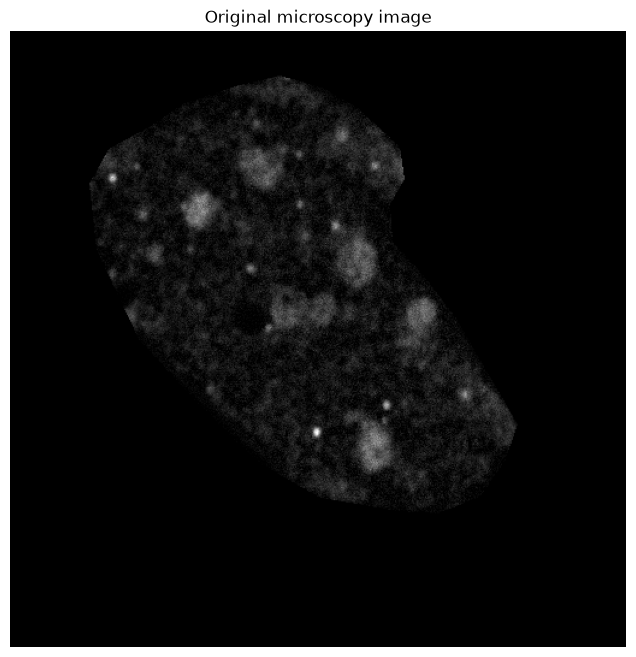

In [4]:
image_path = "training_data/0244.tif"

image = io.imread(image_path)

print("Image shape:", image.shape)
print("Data type:", image.dtype)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image, cmap="gray")
ax.set_title("Original microscopy image")
ax.axis("off")

plt.show()

# Thresholding

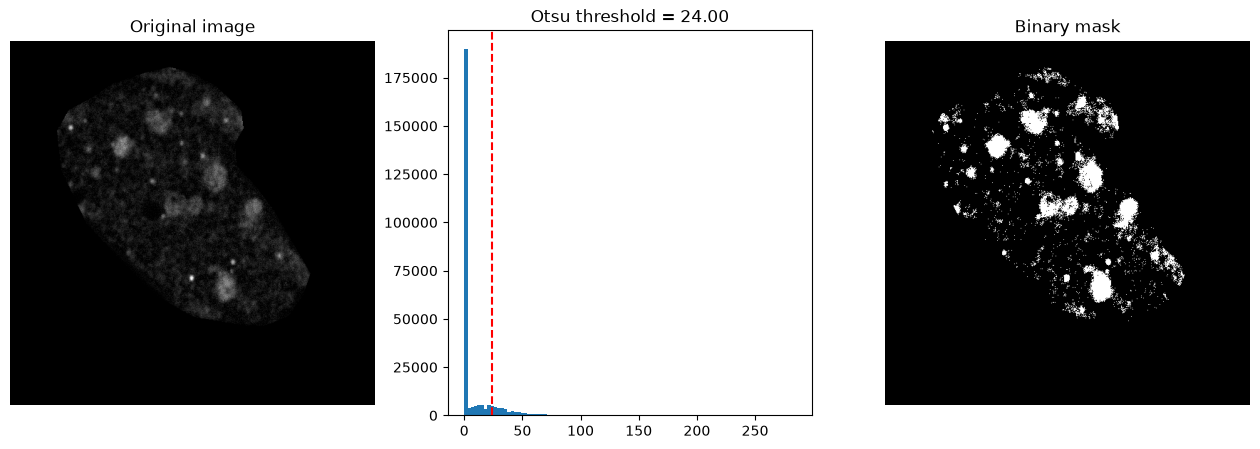

In [5]:
threshold = filters.threshold_otsu(image)
threshold_factor = 2

binary_mask = image > threshold * threshold_factor

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original image")

axes[1].hist(image.ravel(), bins=100)
axes[1].axvline(threshold, color="red", linestyle="--")
axes[1].set_title(f"Otsu threshold = {threshold:.2f}")

axes[2].imshow(binary_mask, cmap="gray")
axes[2].set_title("Binary mask")

for ax in [axes[0], axes[2]]:
    ax.axis("off")

# Cleaning

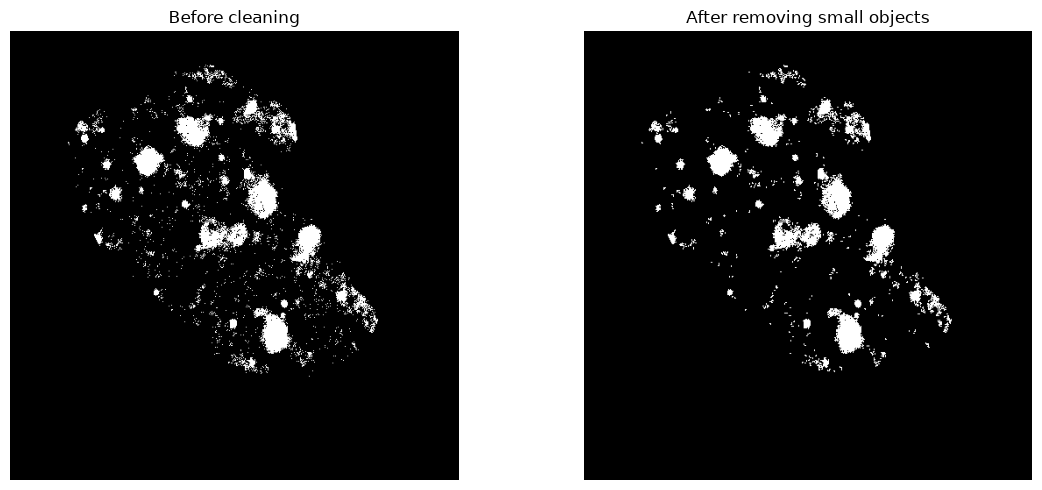

In [6]:
min_area = 2  # pixels

clean_mask = morphology.remove_small_objects(
    binary_mask,
    min_size=min_area
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(binary_mask, cmap="gray")
axes[0].set_title("Before cleaning")

axes[1].imshow(clean_mask, cmap="gray")
axes[1].set_title("After removing small objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Watersheding

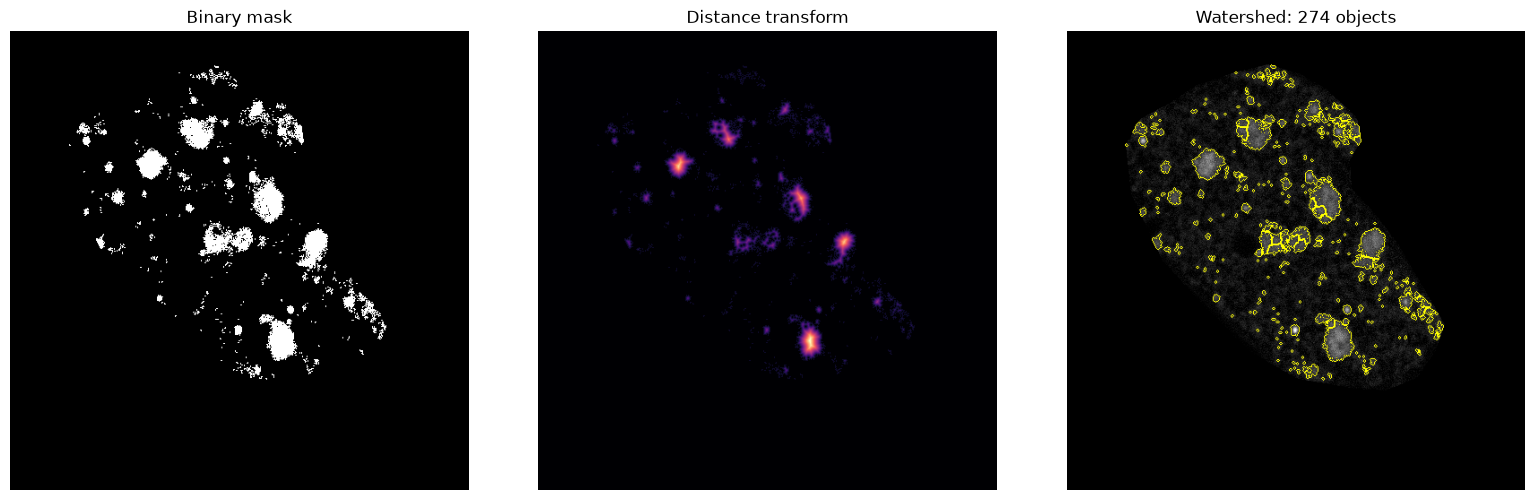

In [7]:
image_float = image.astype(np.float32)

distance = ndi.distance_transform_edt(clean_mask)

# Detect candidate centers
coordinates = peak_local_max(
    distance,
    min_distance=5,
    labels=clean_mask
)

markers = np.zeros_like(clean_mask, dtype=np.int32)

for i, (y, x) in enumerate(coordinates, start=1):
    markers[y, x] = i

labels = segmentation.watershed(
    -distance,
    markers,
    mask=clean_mask
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(clean_mask, cmap="gray")
axes[0].set_title("Binary mask")

axes[1].imshow(distance, cmap="magma")
axes[1].set_title("Distance transform")

axes[2].imshow(
    segmentation.mark_boundaries(
        image_float / (image_float.max() + 1e-8),
        labels
    )
)
axes[2].set_title(f"Watershed: {labels.max()} objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Features analysis

In [21]:
properties = measure.regionprops_table(
    labels,
    intensity_image=image_float,
    properties=[
        "label",
        "area",
        "centroid",
        "equivalent_diameter_area",
        "eccentricity",
        "solidity",
        "perimeter",
        "mean_intensity",
        "max_intensity",
        "min_intensity"
    ]
)

df = pd.DataFrame(properties)

# Circularity: 1 means approximately circular
df["circularity"] = (
    4 * np.pi * df["area"]
    / (df["perimeter"] ** 2 + 1e-8)
)

df["image_id"] = Path(image_path).name

display(df.head())

print("Total detected objects:", len(df))

# Save the DataFrame to a CSV file
df.to_csv("detected_objects.csv", index=False)

,label,area,centroid-0,centroid-1,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,circularity,image_id
0,1,971.0,346.253347,302.725026,35.161280,0.695001,0.854754,193.687338,96.280121,180.0,49.0,0.325257,0244.tif
1,2,737.0,147.782904,157.382632,30.632949,0.453547,0.857974,141.474134,99.483040,186.0,49.0,0.462725,0244.tif
2,3,664.0,236.621988,340.536145,29.076297,0.624589,0.857881,152.089358,88.228912,158.0,49.0,0.360728,0244.tif
3,4,824.0,186.489078,290.175971,32.390576,0.770217,0.770814,200.444697,84.148056,151.0,49.0,0.257720,0244.tif
4,5,675.0,114.567407,211.765926,29.316151,0.580445,0.774971,188.338095,79.770370,138.0,49.0,0.239132,0244.tif


Total detected objects: 274


### Descriptive statistics of data

In [12]:
df.describe()

,label,area,centroid-0,centroid-1,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,circularity
count,274.000000,274.000000,274.000000,274.000000,274.000000,274.000000,274.000000,274.000000,274.000000,274.000000,274.000000,2.740000e+02
mean,137.500000,34.693431,215.433542,252.070447,4.434360,0.851459,0.881687,15.204718,59.778493,76.142336,50.514599,7.429752e+08
std,79.241193,109.017595,99.087698,81.440056,4.959766,0.158003,0.127627,28.883133,10.376542,31.967672,2.488392,1.148959e+09
min,1.000000,2.000000,39.300000,66.333333,1.595769,0.000000,0.586207,0.000000,49.000000,49.000000,49.000000,2.391318e-01
25%,69.250000,2.000000,120.871951,201.083333,1.595769,0.790569,0.775473,0.000000,53.737761,57.000000,49.000000,9.725590e-01
50%,137.500000,5.000000,226.350000,248.333333,2.523133,0.877044,0.883838,4.414214,57.320513,65.000000,50.000000,3.224580e+00
75%,205.750000,22.000000,301.443182,309.877159,5.292567,1.000000,1.000000,16.708631,61.433956,81.000000,51.000000,2.513274e+09
max,274.000000,971.000000,387.333333,416.535714,35.161280,1.000000,1.000000,200.444697,133.594940,285.000000,65.000000,2.513274e+09


## Feature subset and visualization

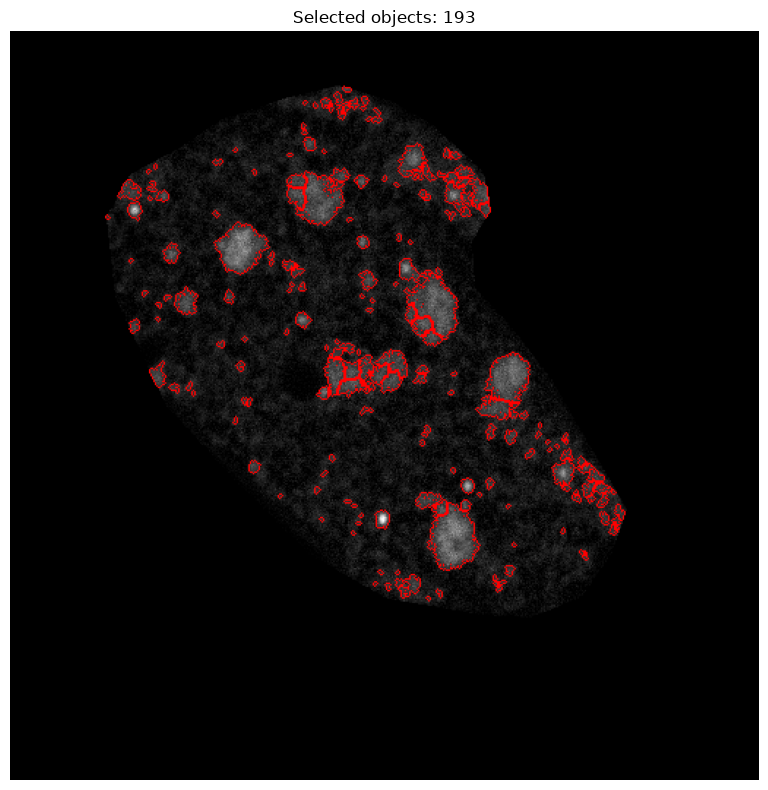

In [55]:
subset = df[(df['area'] > 2.5)]

plot_image(
    image,
    clean_mask,
    labels,
    subset,
    mode="image"
)

In [56]:
inxs = df[df["area"] > 2.5].index.tolist()

print("Number of selected objects:", len(inxs))

Number of selected objects: 193


In [ ]:
show_objects_from_list(
    image,
    labels,
    df,
    inxs,
    padding=10,
    ncols=3
)

### Feature distribution

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "area",
    "equivalent_diameter_area",
    "perimeter",
    "mean_intensity",
    "max_intensity",
    "circularity",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flat, features):
    sns.violinplot(
        data=df,
        x="class",
        y=feature,
        hue="class",
        palette="Set2",
        inner="box",
        legend=False,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel(feature)

for ax in axes.flat[len(features):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))

sc = ax.scatter(
    df["area"],
    df["mean_intensity"],
    c=df["circularity"],
    cmap="viridis",
    s=45,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="Circularity")

ax.set_xlabel("Area (pixels²)")
ax.set_ylabel("Mean fluorescence intensity")
ax.set_title("Morphological features of fluorescent objects")

plt.tight_layout()
plt.show()

### PCA

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

features = [
    "area",
    "mean_intensity",
    "max_intensity",
    "circularity",
    "eccentricity",
    "solidity",
    "perimeter",
    "equivalent_diameter_area"
]

X = df[features].dropna()

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[
        f"PC{i+1}" for i in range(len(features))
    ]
)

display(loadings.round(3))

In [ ]:
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2", "PC3"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [ ]:
df.columns

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

features = [
    "area",
    'perimeter',
    "mean_intensity",
    "max_intensity",
    "circularity",
    "eccentricity",
    "solidity",
]

# Select objects with known classes and complete features
pca_df = df.dropna(subset=features + ["class"]).copy()

X = pca_df[features]

# Standardize features
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="class",
    palette="Set2",
    s=55,
    alpha=0.7
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of Fluorescent Objects")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)

plt.tight_layout()
plt.show()

### Cluster analysis

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import HDBSCAN
from sklearn.metrics import silhouette_score

# PCA coordinates
X = pca_df[["PC1", "PC2"]].to_numpy()

# HDBSCAN clustering
clusterer = HDBSCAN(
    min_cluster_size=25,
    min_samples=10
)

clusters = clusterer.fit_predict(X)

# Add clusters to DataFrame
pca_df = pca_df.copy()
pca_df["cluster"] = clusters

# Number of clusters (excluding noise = -1)
n_clusters = len(set(clusters) - {-1})

print("Number of clusters:", n_clusters)
print("Number of outliers:", np.sum(clusters == -1))

print("\nObjects per cluster:")
print(pca_df["cluster"].value_counts().sort_index())

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    s=55,
    alpha=0.8
)

plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)

plt.title(f"HDBSCAN Clustering: {n_clusters} clusters")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_clusters_on_image(image, pca_df):

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image, cmap="gray")

    clusters = sorted(pca_df["cluster"].dropna().unique())
    cmap = plt.get_cmap("tab20")

    for i, cluster in enumerate(clusters):

        subset = pca_df[pca_df["cluster"] == cluster]

        color = "gray" if cluster == -1 else cmap(i % 20)

        ax.scatter(
            subset["centroid-1"],  # X
            subset["centroid-0"],  # Y
            s=60,
            facecolors="none",
            edgecolors=[color],
            linewidths=1.5,
            label=f"Cluster {int(cluster)}"
        )

    ax.set_title("HDBSCAN clusters on microscopy image")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    ax.axis("off")

    plt.tight_layout()
    plt.show()
    
plot_clusters_on_image(image, pca_df)

In [ ]:
import matplotlib.pyplot as plt

def plot_one_cluster(image, pca_df, cluster_id):

    # Select only objects from the requested cluster
    subset = pca_df[pca_df["cluster"] == cluster_id]

    fig, ax = plt.subplots(figsize=(10, 10))

    # Original microscopy image
    ax.imshow(image, cmap="gray")

    # Highlight selected objects
    ax.scatter(
        subset["centroid-1"],  # X
        subset["centroid-0"],  # Y
        s=60,
        facecolors="none",
        edgecolors="red",
        linewidths=1.5
    )

    ax.set_title(
        f"Cluster {cluster_id} — {len(subset)} objects"
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
plot_one_cluster(image, pca_df, cluster_id=0)

In [ ]:
import matplotlib.pyplot as plt

def plot_selected_clusters(image, pca_df, cluster_ids):

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image, cmap="gray")

    cmap = plt.get_cmap("tab10")

    for i, cluster_id in enumerate(cluster_ids):

        subset = pca_df[pca_df["cluster"] == cluster_id]

        ax.scatter(
            subset["centroid-1"],  # X
            subset["centroid-0"],  # Y
            s=60,
            facecolors="none",
            edgecolors=[cmap(i % 10)],
            linewidths=1.5,
            label=f"Cluster {cluster_id} ({len(subset)} objects)"
        )

    ax.set_title(f"Selected clusters: {cluster_ids}")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
plot_selected_clusters(
    image,
    pca_df,
    cluster_ids=[2, -1]
)

In [ ]:
results = []

for min_size in [5, 10, 15, 20, 30, 40]:
    for min_samples in [3, 5, 10, 20, 30]:

        model = HDBSCAN(
            min_cluster_size=min_size,
            min_samples=min_samples
        )

        labels = model.fit_predict(X)

        mask = labels != -1

        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(~mask)

        # Silhouette score excluding noise
        if n_clusters >= 2 and mask.sum() > n_clusters:
            score = silhouette_score(
                X[mask],
                labels[mask]
            )
        else:
            score = np.nan

        results.append({
            "min_cluster_size": min_size,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "noise_fraction": n_noise / len(X),
            "silhouette": score
        })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "silhouette",
        ascending=False
    )
)

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.lineplot(
    data=results_df,
    x="min_cluster_size",
    y="n_clusters",
    hue="min_samples",
    marker="o",
    palette="viridis",
    ax=ax
)

ax.set_xlabel("Minimum cluster size")
ax.set_ylabel("Number of detected clusters")
ax.set_title("HDBSCAN parameter sensitivity")

plt.tight_layout()
plt.show()

### Correlation analysis

In [ ]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

# Random forest

In [ ]:
from matplotlib.patches import Rectangle

In [ ]:
df

In [ ]:
show_object(image, labels, object_id=7)

In [ ]:
df["class"] = ""

df.to_csv("foci_features_to_label.csv", index=False)

In [ ]:
df_labeled = pd.read_csv("foci_features_to_label.csv")


In [ ]:
df_labeled

In [ ]:
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "solidity",
    "perimeter",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
    "circularity"
]

X = df_labeled[features]
y = df_labeled["class"]

# Train using manually labeled objects
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X, y)

print("Random Forest trained successfully!")